In [1]:

import seaborn  as sns
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("train.csv")     #Read Training Data

In [3]:
print(df.shape)    # Data Shape
print("\n Columns Types: \n")
print(df.dtypes)  # Data Columns Types 

(1000000, 10)

 Columns Types: 

id                     object
vendor_id               int64
pickup_datetime        object
passenger_count         int64
pickup_longitude      float64
pickup_latitude       float64
dropoff_longitude     float64
dropoff_latitude      float64
store_and_fwd_flag     object
trip_duration           int64
dtype: object


In [4]:
df.head()

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2793718,2,2016-06-08 07:36:19,1,-73.985611,40.735943,-73.980331,40.760468,N,1040
1,id3485529,2,2016-04-03 12:58:11,1,-73.978394,40.764351,-73.991623,40.749859,N,827
2,id1816614,2,2016-06-05 02:49:13,5,-73.989059,40.744389,-73.973381,40.748692,N,614
3,id1050851,2,2016-05-05 17:18:27,2,-73.990326,40.731136,-73.991264,40.748917,N,867
4,id0140657,1,2016-05-12 17:43:38,4,-73.789497,40.646675,-73.987137,40.759232,N,4967


In [5]:
df.describe()    #Statistices For Fhe Data

,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1.000000e+06
mean,1.534793,1.665353,-73.973475,40.750947,-73.973421,40.751829,9.548850e+02
std,0.498788,1.315723,0.065404,0.033745,0.065432,0.035782,3.882070e+03
min,1.000000,0.000000,-121.933342,34.359695,-121.933304,34.359695,1.000000e+00
25%,1.000000,1.000000,-73.991852,40.737372,-73.991341,40.735928,3.970000e+02
50%,2.000000,1.000000,-73.981728,40.754131,-73.979767,40.754551,6.620000e+02
75%,2.000000,2.000000,-73.967346,40.768379,-73.963036,40.769833,1.074000e+03
max,2.000000,7.000000,-61.335529,51.881084,-61.335529,43.921028,2.227612e+06


In [6]:
df.isna().sum()  # Explore If There are Missing Values in data

id                    0
vendor_id             0
pickup_datetime       0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

In [7]:
df["pickup_datetime"]=pd.to_datetime(df["pickup_datetime"])       # convert pickup_datetime to datetime to extract time features 
df["pickup_hour"]=df["pickup_datetime"].dt.hour                   # add new feature contains pickup_hour
df["pickup_minute"]=df["pickup_datetime"].dt.minute               # add new feature contains pickup_minute
df["pickup_month"]=df["pickup_datetime"].dt.month                 # add new feature contains pickup_month
df["is_weekend"]=df["pickup_datetime"].dt.dayofweek.isin([4,5])   # add new feature to know it is weekend or no 
df["pickup_day"]=df["pickup_datetime"].dt.dayofweek               # add new feature for the name day
def get_season(month):                                            #function to get the season from month
        if month in [12, 1, 2]:
            return 'Winter'  
        elif month in [3, 4, 5]:
            return 'Spring'  
        elif month in [6, 7, 8]:
            return 'Summer'  
        else:
            return 'Fall'    
df['season'] = df['pickup_month'].apply(get_season)              #apply the func on the pickup_month column

In [8]:
# from pickup_longitude,dropoff_longitude,dropoff_longitude and dropoff_latitude we can extract new feature give us Haversine distance
def Haversine_func(long1,lati1,long2,lati2):                              # func that calculates Haversine distance
        lati1,lati2=np.radians(lati1),np.radians(lati2)
        long=np.radians(long2-long1)
        lati=lati2-lati1
        a=np.sin(lati/2)**2+np.cos(lati1)*np.cos(lati2)*np.sin(long/2)**2
        c=2*np.arcsin(np.sqrt(a))
        d=c*6371.0
        return d
df["Haversine_Distance"]=Haversine_func(df["pickup_longitude"],df["pickup_latitude"],df["dropoff_longitude"],df["dropoff_latitude"])   # add Haversine distance as feature

<Axes: xlabel='trip_duration', ylabel='Count'>

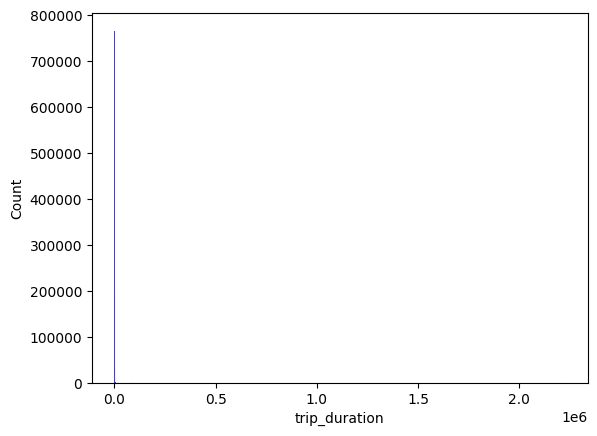

In [11]:
sns.histplot(df["trip_duration"],color="blue")

In [12]:
#target  is highly right skewed 
# rescale the target to have normal_dist
df['trip_duration']=np.log1p(df['trip_duration'])

<Axes: xlabel='trip_duration', ylabel='Count'>

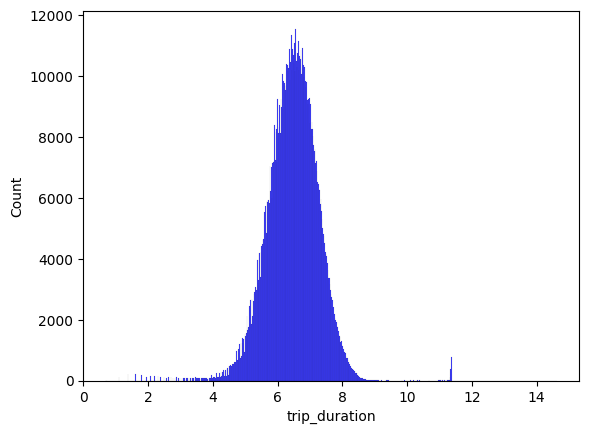

In [13]:
sns.histplot(df["trip_duration"],color="blue")

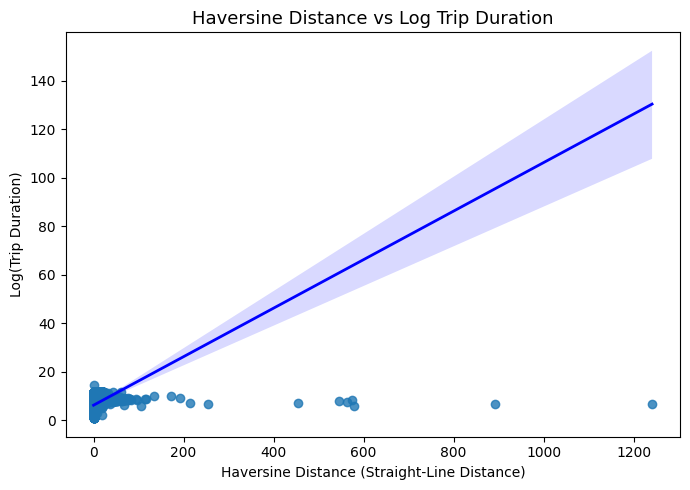

In [14]:
plt.figure(figsize=(7, 5))
sns.regplot(
    data=df,
    x='Haversine_Distance',
    y='trip_duration',
    line_kws={'color': 'blue', 'linewidth': 2}
)

plt.title("Haversine Distance vs Log Trip Duration", fontsize=13)
plt.xlabel("Haversine Distance (Straight-Line Distance)")
plt.ylabel("Log(Trip Duration)")
plt.tight_layout()
plt.show()

In [15]:
# high variance  in time_duration for almost equel haversine distance 
#add anathor feature explore the distance from other angle (Manhattan Distance)
def Manhattan_func(long1,lati1,long2,lati2):   #func to calculate Manhattan Distance
        r=6371.0
        long1,lati1,long2,lati2=map(np.radians,[long1,lati1,long2,lati2])
        return (np.abs(lati1-lati2)*r+np.abs(long1-long2)*r*np.cos((lati1+lati2)/2))
# add Manhattan Distance as a feature    
df["Manhattan_Distance"]=Manhattan_func(df["pickup_longitude"],df["pickup_latitude"],df["dropoff_longitude"],df["dropoff_latitude"]) 

In [16]:
df.select_dtypes(["object","bool"])  

,id,store_and_fwd_flag,is_weekend,season
0,id2793718,N,False,Summer
1,id3485529,N,False,Spring
2,id1816614,N,False,Summer
3,id1050851,N,False,Spring
4,id0140657,N,False,Spring
...,...,...,...,...
999995,id2875371,N,True,Spring
999996,id1038420,N,False,Spring
999997,id3238884,N,False,Spring
999998,id3652642,N,False,Spring


In [17]:
df.drop(columns=("id"))  # remove id column 
df["is_weekend"]=df["is_weekend"].astype("int")  # convert to type int 
df['store_and_fwd_flag'] =(df['store_and_fwd_flag'].str.lower().eq('y').astype("int")) # convert to type int 
df=pd.get_dummies(df,columns=["season"],drop_first=False,dtype=int) # tranform columns season to one hat encoders

In [18]:
# we can invaint also new features to incraies performance
df["lati_diff"]=np.abs(df["dropoff_latitude"]-df["pickup_latitude"])      #diff between latitude
df["long_diff"]=np.abs(df["dropoff_longitude"]-df["pickup_longitude"])    #diff between longitude
df["area_bounding_box"]= df["lati_diff"]* df["long_diff"]                 #The area formed by diff latitude diff longitude
df["distance_rathio"]=(df["Manhattan_Distance"]/(df["Haversine_Distance"]+0.001)) # rethio between the two distance features
df["distance_diff"]=df["Manhattan_Distance"]-df["Haversine_Distance"]             # diff detween the two distance features
df['sin_hour'] = np.sin(2 * np.pi * df["pickup_hour"] / 24.0)
df['cos_hour'] = np.cos(2 * np.pi * df["pickup_hour"] / 24.0)
df['is_rush_hour'] = df['pickup_hour'].isin([7, 8, 9, 16, 17, 18, 19]).astype(int) # is the pick up hour is rush or no
df['Manhattan intersect Haversine'] =df["Manhattan_Distance"]*df["Haversine_Distance"] #thes feature makes an a intersect betwen the two distance features
df=df.drop(columns=["vendor_id","id","pickup_datetime"],errors='ignore')

In [19]:
df=df.drop(columns=["vendor_id","pickup_datetime"],errors='ignore')  #remove features (unimportant)

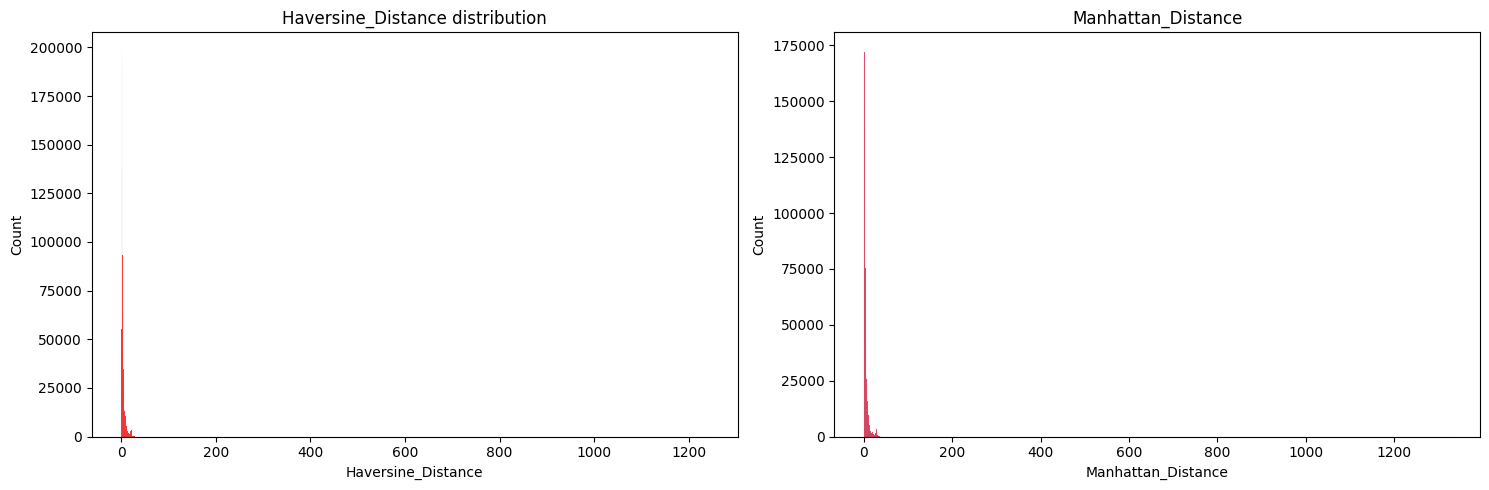

In [20]:
fig,axes=plt.subplots(1,2,figsize=(15,5))
axes=axes.flatten()
sns.histplot(df["Haversine_Distance"],ax=axes[0], color='red')
axes[0].set_title("Haversine_Distance distribution")
sns.histplot(df["Manhattan_Distance"],ax=axes[1], color='crimson')
axes[1].set_title("Manhattan_Distance")
plt.tight_layout()
plt.show()


In [21]:
#columns highly skewed 
#apply log to make anormal dise

In [22]:
df["Haversine_Distance"],df["Manhattan_Distance"]=np.log1p(df["Haversine_Distance"]),np.log1p(df["Manhattan_Distance"])

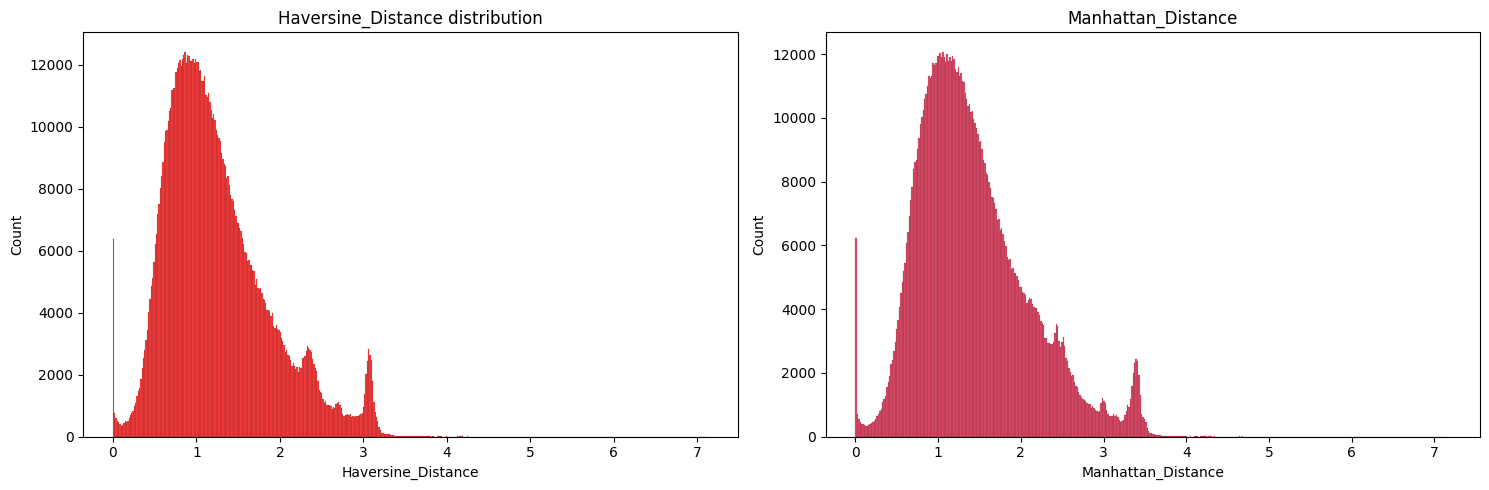

In [23]:
fig,axes=plt.subplots(1,2,figsize=(15,5))
axes=axes.flatten()
sns.histplot(df["Haversine_Distance"],ax=axes[0], color='red')
axes[0].set_title("Haversine_Distance distribution")
sns.histplot(df["Manhattan_Distance"],ax=axes[1], color='crimson')
axes[1].set_title("Manhattan_Distance")
plt.tight_layout()
plt.show()

<Axes: ylabel='trip_duration'>

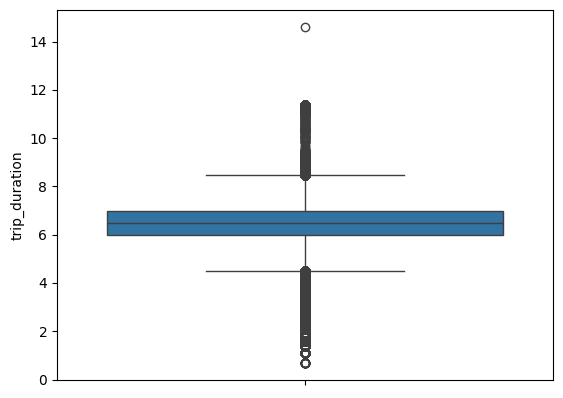

In [24]:
sns.boxplot(df["trip_duration"]) # explore if there are  outliers will effect on the model training

In [25]:
def remove_outliers(log_duration):               #func to remove the outliers
        q1 = log_duration.quantile(0.25)
        q3 = log_duration.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        
        clean_mask = ((log_duration>= lower_bound) & (log_duration <= upper_bound))
        
        df_clean = df[clean_mask].copy()
        return df_clean
df=remove_outliers(df["trip_duration"])      # remove outliers from the trip_duration 

<Axes: ylabel='trip_duration'>

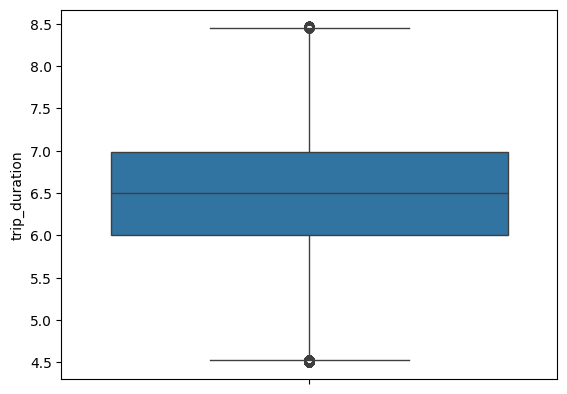

In [26]:
sns.boxplot(df["trip_duration"])

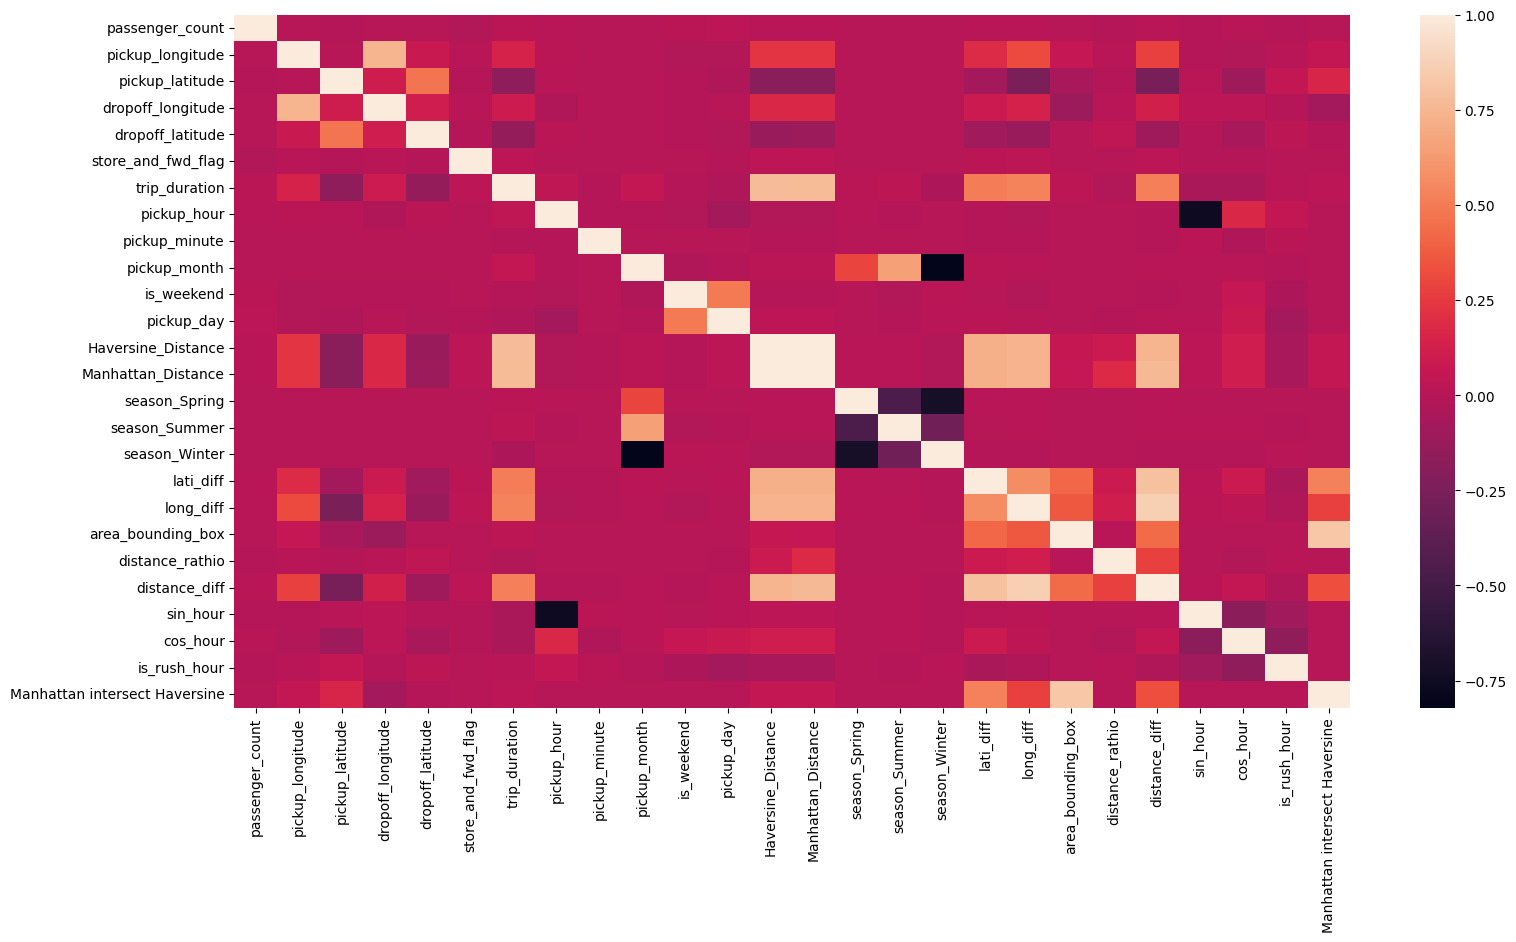

In [27]:
plt.figure(figsize=(18,9))
sns.heatmap(df.corr())
plt.show()
